# Scalar diffraction with FFTs

This notebook checks `diffract` against closed-form results:

1. the Airy pattern of a circular aperture,
2. single- and double-slit Fraunhofer patterns,
3. the transition from near field to far field as the Fresnel number drops,
4. the Talbot self-imaging carpet of a grating,
5. Gaussian-beam spreading under angular-spectrum propagation.

All lengths are in micrometres.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
import diffract as df

WL = 0.5

## 1. Airy pattern

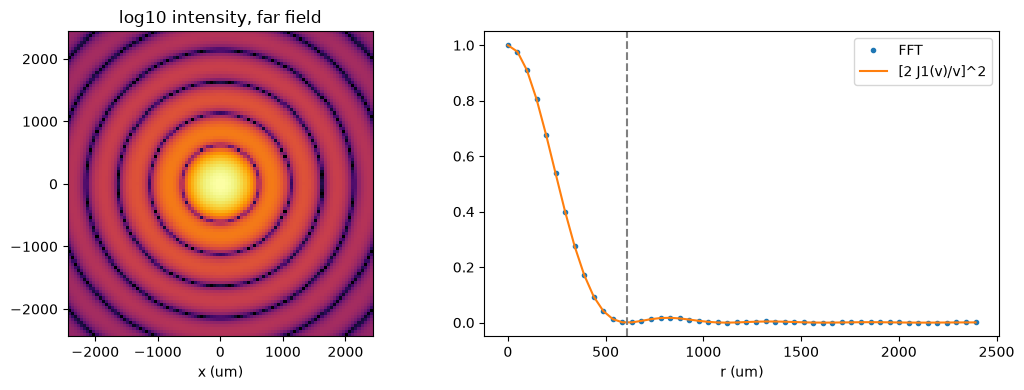

first dark ring at 609.8 um; encircled energy there = 0.8378


In [2]:
g = df.Grid(2048, 0.5)
mask = df.circular_aperture(g, 100.0)
d_eff = np.sqrt(4 * mask.sum() * g.dx**2 / np.pi)
z = 1e5
u, g2 = df.fraunhofer(mask, g, WL, z)
I = df.intensity(u); I /= I.max()
c = g2.n // 2
r = g2.x[c:]
r1 = df.airy_zero_radius(WL, d_eff, z)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
span = 4 * r1
sl = np.abs(g2.x) < span
axes[0].imshow(np.log10(I[np.ix_(sl, sl)] + 1e-6), extent=[-span, span, -span, span], cmap="inferno")
axes[0].set_title("log10 intensity, far field"); axes[0].set_xlabel("x (um)")
keep = r < span
axes[1].plot(r[keep], I[c, c:][keep], "o", ms=3, label="FFT")
axes[1].plot(r[keep], df.airy_pattern(r[keep], WL, d_eff, z), label="[2 J1(v)/v]^2")
axes[1].axvline(r1, ls="--", c="gray"); axes[1].set_xlabel("r (um)"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"first dark ring at {r1:.1f} um; encircled energy there = {float(df.airy_encircled_energy(r1, WL, d_eff, z)):.4f}")

## 2. Single and double slit

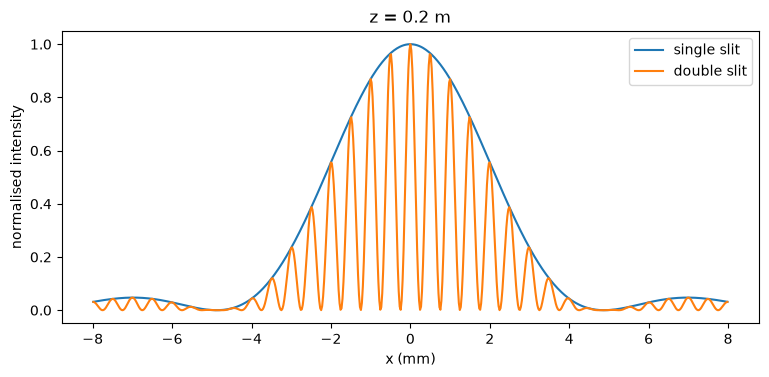

In [3]:
g1 = df.Grid(8192, 0.5, ndim=1)
z = 2e5
fig, ax = plt.subplots(figsize=(9, 3.8))
for name, m, a in [("single slit", df.slit(g1, 20.0), None), ("double slit", df.double_slit(g1, 20.0, 200.0), 200.0)]:
    u, g2 = df.fraunhofer(m, g1, WL, z)
    I = df.intensity(u); I /= I.max()
    keep = np.abs(g2.x) < 8000
    ax.plot(g2.x[keep] / 1000, I[keep], label=name)
ax.set_xlabel("x (mm)"); ax.set_ylabel("normalised intensity"); ax.legend(); ax.set_title(f"z = {z/1e6:.1f} m")
plt.show()

## 3. From Fresnel to Fraunhofer

A 200 um square aperture propagated with the angular spectrum method. The
Fresnel number $N_F = a^2/(\lambda z)$ falls from about 20 to about 0.2.

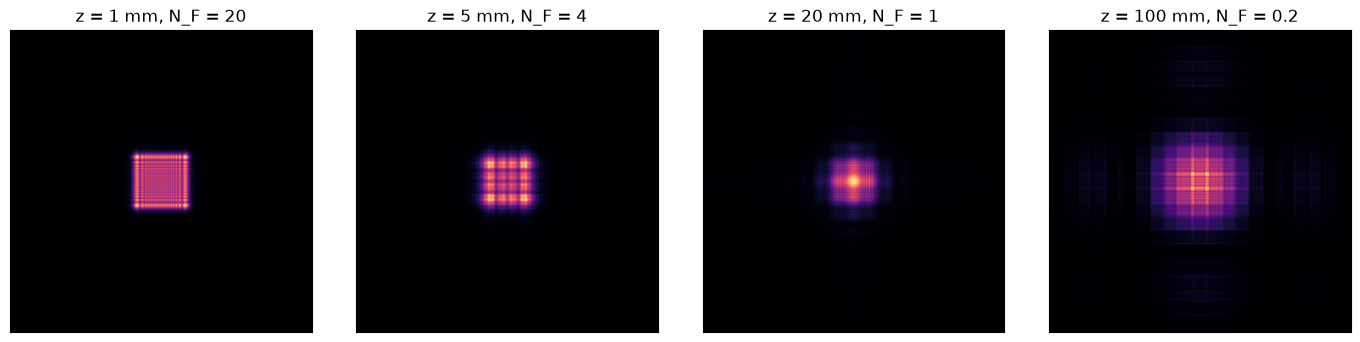

In [4]:
g = df.Grid(1024, 1.0)
sq = df.rectangular_aperture(g, 200.0, 200.0)
zs = [1e3, 5e3, 2e4, 1e5]
fig, axes = plt.subplots(1, len(zs), figsize=(14, 3.4))
for ax, z in zip(axes, zs):
    I = df.intensity(df.angular_spectrum(sq, g, WL, z))
    ax.imshow(I, extent=[g.x[0], g.x[-1], g.x[0], g.x[-1]], cmap="magma")
    ax.set_title(f"z = {z/1e3:g} mm, N_F = {df.fresnel_number(100.0, WL, z):.2g}")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 4. Talbot carpet

A binary grating re-images itself after $z_T = 2d^2/\lambda$, and is shifted by half a period at $z_T/2$.

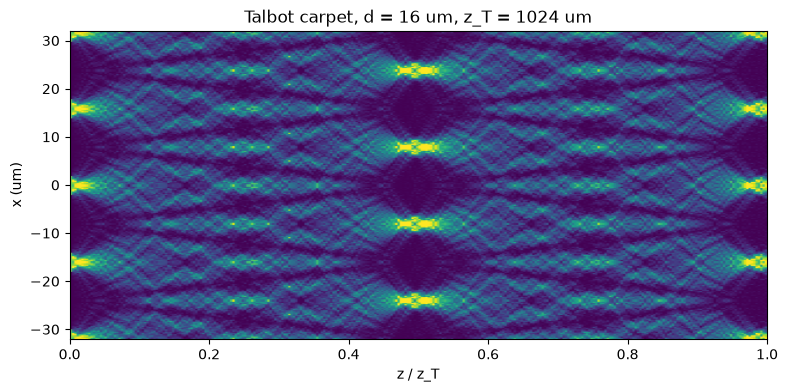

In [5]:
period = 16.0
g1 = df.Grid(2048, 0.25, ndim=1)
u0 = df.grating(g1, period, period / 4)
zT = df.talbot_distance(period, WL)
zz = np.linspace(0, zT, 300)
carpet = np.array([df.intensity(df.angular_spectrum(u0, g1, WL, zi)) for zi in zz])
win = np.abs(g1.x) <= 2 * period
plt.figure(figsize=(9, 4))
plt.imshow(carpet[:, win].T, aspect="auto", origin="lower", cmap="viridis",
           extent=[0, 1, g1.x[win][0], g1.x[win][-1]], vmax=np.percentile(carpet, 99.5))
plt.xlabel("z / z_T"); plt.ylabel("x (um)"); plt.title(f"Talbot carpet, d = {period:g} um, z_T = {zT:.0f} um")
plt.show()

## 5. Gaussian beam spreading

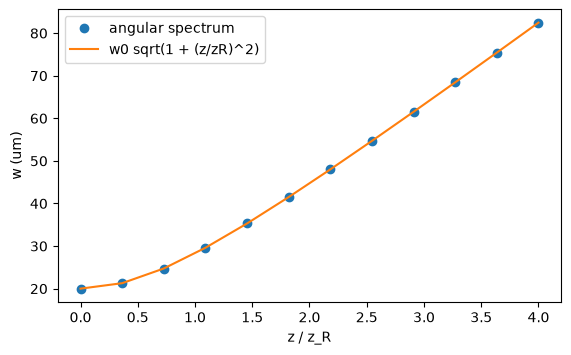

max relative error: 2.9801780207838746e-05


In [6]:
g = df.Grid(512, 1.0)
w0 = 20.0
u0 = df.gaussian_beam(g, w0)
zr = df.rayleigh_range(w0, WL)
zs = np.linspace(0, 4 * zr, 12)
w_num = [df.second_moment_width(df.angular_spectrum(u0, g, WL, z), g) for z in zs]
plt.figure(figsize=(6.5, 3.8))
plt.plot(zs / zr, w_num, "o", label="angular spectrum")
plt.plot(zs / zr, df.gaussian_width(w0, WL, zs), label="w0 sqrt(1 + (z/zR)^2)")
plt.xlabel("z / z_R"); plt.ylabel("w (um)"); plt.legend(); plt.show()
print("max relative error:", np.max(np.abs(np.array(w_num) / df.gaussian_width(w0, WL, zs) - 1)))